# E79: Is E76's masked fall agreement or softness, and can a masked read credit a placement?

*2026-11-04, D1, `qwen-decomp-lead`. D1 is a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement. Record: `reports/analyses/2026-11-04_analysis_e79-masked-read.md`. Checks: `reports/reviews/2026-11-04_review_e79-a1-check.md`.*

**The answer.** Recomputing the masks on a forward near the fine-tuned model gets nearly all of the masked fall, with nothing placed under them. Leaving the update out of the subcomponents altogether reads at least as well as the clean-term change. So a low reading under recomputed masks can penalise harm, but it cannot credit a placement. That change has shown only clean agreement, at about half the update's squared size. The largest fall under frozen masks is mixed, and D1 still has neither map nor test.

Independent check of Amendment 2: numbers and verdicts recompute, code paths as filed, wording corrected as below.

**Something unexpected happened that I cannot explain.** We leaned that the all-masked change's fall would be agreement, and it read mixed. Then the original model's unchanged weights, under masks computed on another forward, landed near the fine-tuned model. Two readings fit that, and this job does not separate them.


## What we were trying to test

E76 trained small changes to the subcomponents of W0, Qwen3-1.7B before the update, so that the changed model copies FT, the fine-tuned model, W0 plus the update δW. Its masked number fell far, but that number rewards a soft output. This job trained nothing and read the saved states.

**The states.** A, B and L are each the decomposition after teacher training towards FT, with about 200 columns per matrix moved.

- **A** trained on the clean term alone, at 0.52 of δW's squared size.
- **B** added a masked term with all 196 matrices masked, at 3.4 times δW's size.
- **L** added a masked term under the library's routing, at 2.4 times.
- **P** is A's change with columns permuted within each site, then scaled to A's size. It is a known bad placement.
- **C** is E76's control, trained towards W0 plus a random change. It is another known bad placement.
- **N** is do-nothing: FT's weights, components unmoved, δW in Δ.
- **Z** is W0's weights with nothing placed, under A's masks. It asks whether A's masks alone carry the fall.

**The masks.** Each subcomponent is multiplied by $m = g + (1-g)u$, with $g$ the causal importance from Γ and $u$ uniform on 0 to 1, and a share of Δ is added. Frozen masks take $g$ from Γ on W0's forward, whatever is read. Own masks take $g$ from Γ on the state's own forward.

**The numbers.** The read is forward KL(FT clean ‖ state masked): 0 means the masked output is FT's clean output, and it rewards softness. Clean is KL(FT clean ‖ state clean), which is blind to masks. Self is KL(state clean ‖ state masked), blind to how far the state sits from FT. Reverse KL punishes softness. Top-token agreement is blind to confidence. Entropy does not say where softness sits.

**The rows.** M is eight unseen maths rows and W is eight unseen web text rows, 256 tokens each.

**Three jobs, each asked by the last.** The first read frozen and own masks on A, B and L. A read so well under own masks that the second asked whether that read has teeth, using P and C. An independent check then found its rules never read do-nothing, so the third read N and Z.

## What we expected, and why

We leaned that B's fall was agreement and held on web text, since it already sat under the best temperature read on other rows. We leaned, weakly, that own masks open many more subcomponents on A, since 1.33 to 0.078 for so small a change wanted explaining. Before the third job we leaned that N reads as A or lower, and that A's masks alone carry the fall.

## What we observed

### What moves the masked read: the masks, or the change placed under them?


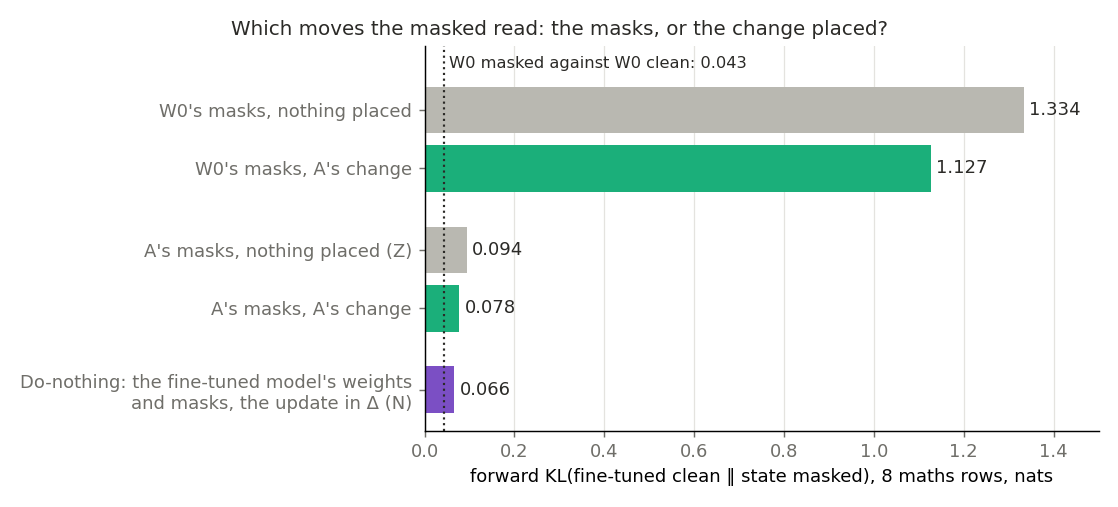

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_masked_read")
RES, FIG = ROOT / "results", ROOT / "figures"

def load(name):
    return json.loads((RES / name).read_text())

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

READ, A1, A2, ROWS = (load(f) for f in ("read.json", "amend1.json", "amend2.json", "rows.json"))
R, O, N = READ["reads"], A1["reads"], A2["reads"]

show("two_by_two.png")


**Reading it.** The masks do. Under W0's masks, A's change moves the read from 1.334 to 1.127. Under A's masks, removing A's change moves it only from 0.078 to 0.094. So A's masks alone give 0.987 of A's fall, on W0's unchanged weights. Do-nothing reads 0.066, the lowest of the five.

The filed verdict on N against A is "same": the difference of -0.0114 is inside the band of 0.0127. That is conservative, because N is below A on 8 of 8 maths rows, and the band is W0's spread between draws at a reading near 1.33. A tighter band gives "do-nothing beats A", the same branch of the filed outcome.

Z is not softness: its agreement with FT is 0.914 and its reverse KL 0.072, with entropy 1.37 against FT's 1.53.

**Two readings of Z fit equally, and neither is claimed.** Γ may be a channel for whatever forward it reads. Or the update's behaviour may really be a change in which existing subcomponents Γ switches on. Even the second meets the elicitation granularity limit: a new circuit built from old subcomponents reads as elicited to VPD. W0 under masks from an unrelated changed forward would separate them, and it was not read.


In [2]:
def read(cell):
    return cell["all"]
cells = [("W0, W0's masks", O["W0"]["M"]["d1"]), ("A's change, W0's masks", R["A"]["M"]["d1"]), ("Z, A's masks", N["Z"]["M"]["d1"]), ("A's change, A's masks", O["A"]["M"]["d1"]), ("N, FT's masks", N["N"]["M"]["d1"])]
table(["on M", "read", "reverse KL", "agreement", "entropy"], [[k, f"{read(c)['fwd']:.3f}", f"{read(c)['rev']:.3f}", f"{read(c)['agree']:.3f}", f"{read(c)['H']:.2f}"] for k, c in cells] + [["FT clean", 0, 0, 1, f"{read(R['FT']['M']['clean'])['H']:.2f}"]])
print("N below A on", ROWS["N_below_A_rows"], "of 8 maths rows")


| on M | read | reverse KL | agreement | entropy |
|---|---|---|---|---|
| W0, W0's masks | 1.334 | 0.623 | 0.799 | 0.61 |
| A's change, W0's masks | 1.127 | 0.586 | 0.806 | 0.69 |
| Z, A's masks | 0.094 | 0.072 | 0.914 | 1.37 |
| A's change, A's masks | 0.078 | 0.069 | 0.915 | 1.56 |
| N, FT's masks | 0.066 | 0.056 | 0.924 | 1.49 |
| FT clean | 0 | 0 | 1 | 1.53 |

N below A on 8 of 8 maths rows


### Is the own-mask read anything beyond clean plus self?


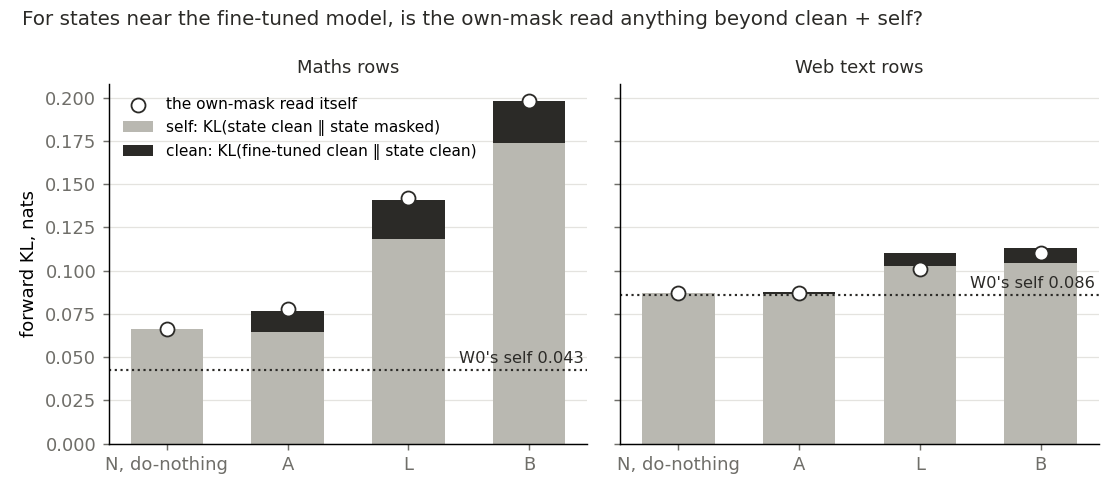

In [3]:
show("own_split.png")


**Reading it.** Not for states near FT. A's clean and self sum to 0.0767 on maths rows, against a read of 0.0776, and N is all self. On web text every state sits near W0's self of 0.086, the worst fit being L's. The split does not hold far from FT: W0, P, C and Z read well under their sums on maths rows.

The filed outcome label, "credits any forward near FT", stays as filed and is not the claim, for two reasons. Z is not a forward near FT: it is W0's forward under masks made from one. And B and L are near FT, with clean 0.024 and 0.023, yet read 0.198 and 0.142, over twice N's. The claim is the check's: do-nothing reads at least as well as A, and A's masks on W0's unchanged weights read 0.094, so a low own-mask read is no evidence of placement. It can penalise harm; it cannot credit placement.

### What could "passes all three" see?


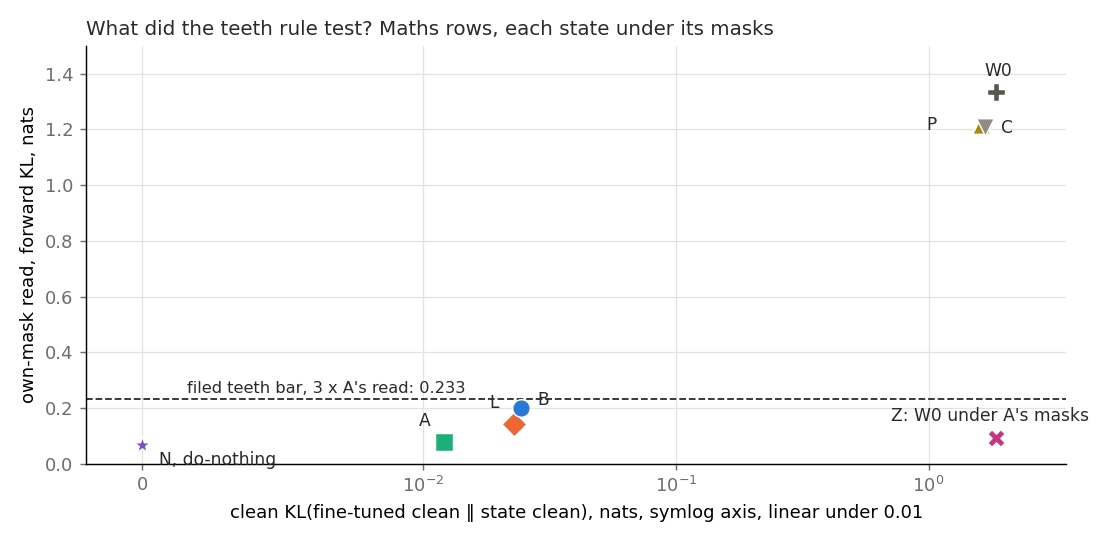

In [4]:
show("teeth.png")


**Reading it.** The filed verdict "passes all three" stands, and the rules could not see what mattered. Teeth was inherited from the clean table: P and C fail only because their clean outputs are far from FT. In the figure the far states sit top right and the near states bottom left. Nobody tried a state near FT with a wrong placement until N, the lowest of all. Faithful would also pass P and C. Opens reads only a net mean, 0.993 for A, which hides movement per position.

### Under frozen masks, is the fall agreement or softness?


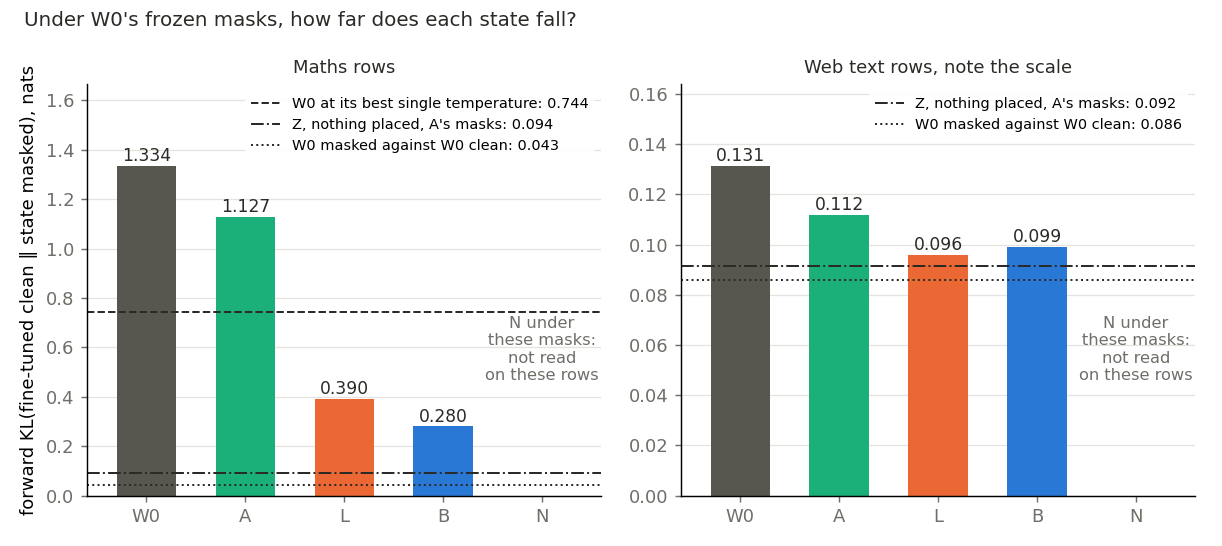

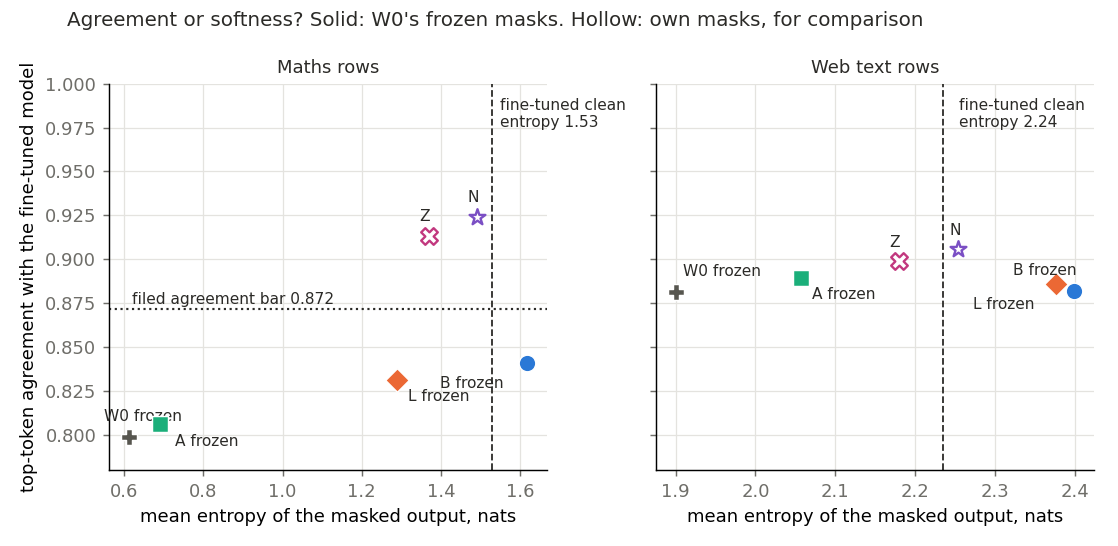

In [5]:
show("frozen.png")
show("agree_soft.png")


**Reading it.** Mixed, for both B and L, on maths rows. Neither is softness: both sit well under W0's best single temperature, 0.744, and reverse KL is under half W0's. Neither is agreement: top-token agreement reads 0.841 and 0.832, short of the filed bar of 0.872.

On web text the fall does not survive, by the filed rule, and B overshoots softness, with entropy 2.40 against FT's 2.24. Half of B's training rows were web text, with the masked term on them. The caveat is room: W0's self there is 0.086, and the rule needs a reading near 0.066, which even do-nothing's own-mask 0.087 misses.

Frozen W0 masks remain the one read here where placements differ widely, and they are still not D1's map. Z shows W0's masks hold most of the 1.334, so frozen numbers measure offsets working against those masks. The ranking stands, but B's 0.280 at 3.4 times δW's size is worse than Z's 0.094 with nothing placed. N was not read under these masks on these rows. E72's reads with Δ on, 1.262 and 1.108, suggest it stays high, but those are other rows and not like for like. B was also trained with this very term in its loss.


In [6]:
table(["frozen masks", "read on M", "agreement on M", "read on W", "entropy on W"], [[s, f"{read(R[s]['M']['d1'])['fwd']:.3f}", f"{read(R[s]['M']['d1'])['agree']:.3f}", f"{read(R[s]['W']['d1'])['fwd']:.3f}", f"{read(R[s]['W']['d1'])['H']:.2f}"] for s in ("W0", "A", "L", "B")] + [["FT clean", 0, 1, 0, f"{read(R['FT']['W']['clean'])['H']:.2f}"]])


| frozen masks | read on M | agreement on M | read on W | entropy on W |
|---|---|---|---|---|
| W0 | 1.334 | 0.799 | 0.131 | 1.90 |
| A | 1.127 | 0.806 | 0.112 | 2.06 |
| L | 0.390 | 0.832 | 0.096 | 2.38 |
| B | 0.280 | 0.841 | 0.099 | 2.40 |
| FT clean | 0 | 1 | 0 | 2.24 |

## What we learned

The own-mask read is not a test of placement for D1. A's good own-mask number says nothing for A over do-nothing or over B, and what A has shown is only clean agreement, at 0.52 of the update's squared size. The read can still penalise harm. B's frozen-mask fall is real on maths rows, neither plain softness nor agreement, and it does not hold on web text.

For D1, ask 24 stands: the clean-model table is D1's table, and teacher training with masks in its loss is the map. One fact goes to the user. The clean table cannot fail do-nothing, since do-nothing is FT's clean behaviour by construction: N reads about 1e-9. This write-up proposes no fix.

## How compelling is the evidence

One update, one seed, 16 rows, about 200 columns per matrix, and one draw for N and Z. On web text the unfiled share for Z is 0.89, with little room. No number reads which subcomponents move. N is Δ's best case, since Δ opens under the mask. A is not a decomposition of the fine-tuned weights: its squared distance to them is 4.75, against W0's 3.49. Two independent checks recomputed the means and rules from saved arrays and found no bug, and neither reran a model.

## Surprises

The filed leans on B and L reading agreement, and on B surviving on web text, were false. The lean that A opens was false. Z is the one I cannot explain, as above. A beat B on every number under own masks, the reverse of frozen masks; Amendment 2 shows that is no result for A.

## What next

1. **The user's call on D1's test.** The clean table cannot fail do-nothing, and the own-mask read cannot credit a placement. The lead takes this to the user.
2. **W0 under masks from an unrelated changed forward.** If W0 lands near that forward too, the channel reading gains. If not, the fall is specific to this forward.
3. **N under W0's frozen masks on these rows.** If it stays near 1.33, frozen masks separate do-nothing from B. If it falls, their spread says less than it seems to.

## Scorecard


In [7]:
sc, s1, s2 = READ["score"], A1["score"], A2["score"]
table(["id", "claim", "read", "verdict"], [
    ["B", "agreement, softness or mixed; lean agreement", f"{read(R['B']['M']['d1'])['fwd']:.3f}, agreement {read(R['B']['M']['d1'])['agree']:.3f}", f"{sc['B']['label']}; lean false"],
    ["L", "same; lean agreement", f"{read(R['L']['M']['d1'])['fwd']:.3f}, agreement {read(R['L']['M']['d1'])['agree']:.3f}", f"{sc['L']['label']}; lean false"],
    ["W", "fall holds on web text; lean survives for B", f"B {read(R['B']['W']['d1'])['fwd']:.3f}, L {read(R['L']['W']['d1'])['fwd']:.3f}", f"{sc['B']['W']}, {sc['L']['W']}; lean false"],
    ["own", "B within 1.5 x frozen under own masks", f"{read(R['B']['M']['own'])['fwd']:.3f}", f"{sc['B']['own']}; lean held"],
    ["A1 opens", "A's ratio above 1.5; lean opens", f"{s1['ratios']['A']['M']['sum_g']:.3f}", f"{s1['opens']}; lean false"],
    ["A1 teeth", "P, C at least 3 x A's read", f"{read(O['P']['M']['d1'])['fwd']:.3f}, {read(O['C']['M']['d1'])['fwd']:.3f}", f"{s1['teeth']['P']}, {s1['teeth']['C']}; lean held"],
    ["A1 faithful", "A's self at most 2 x W0's, M and W", f"{read(O['A']['M']['d1'])['self_fwd']:.4f}, {read(O['A']['W']['d1'])['self_fwd']:.4f}", f"{s1['faithful']['M']}, {s1['faithful']['W']}; leans held"],
    ["A1 outcome", "all three", "", f"{s1['outcome']}, stands as filed"],
    ["A2 do-nothing", "N minus A against 3 b", f"{s2['N_own_minus_A_own']:.4f}, band {3 * s2['b']:.4f}", f"{s2['do_nothing']}; lean held"],
    ["A2 masks alone", "share at least 0.9", f"{s2['s']:.3f}", f"{s2['masks_alone']}; lean held"],
    ["A2 outcome", "filed label", "", f"\"{s2['outcome']}\", stands as filed, not the claim"],
])


| id | claim | read | verdict |
|---|---|---|---|
| B | agreement, softness or mixed; lean agreement | 0.280, agreement 0.841 | mixed; lean false |
| L | same; lean agreement | 0.390, agreement 0.832 | mixed; lean false |
| W | fall holds on web text; lean survives for B | B 0.099, L 0.096 | does not survive, does not survive; lean false |
| own | B within 1.5 x frozen under own masks | 0.198 | survives; lean held |
| A1 opens | A's ratio above 1.5; lean opens | 0.993 | does not open; lean false |
| A1 teeth | P, C at least 3 x A's read | 1.216, 1.208 | teeth, teeth; lean held |
| A1 faithful | A's self at most 2 x W0's, M and W | 0.0646, 0.0865 | faithful, faithful; leans held |
| A1 outcome | all three |  | passes all three, stands as filed |
| A2 do-nothing | N minus A against 3 b | -0.0114, band 0.0127 | same; lean held |
| A2 masks alone | share at least 0.9 | 0.987 | masks alone; lean held |
| A2 outcome | filed label |  | "credits any forward near FT", stands as filed, not the claim |

## Departures from the literature

Against VPD's fit of this decomposition and its evaluation:

- **Frozen masks on a changed model.** VPD takes masks from Γ on the model being read.
- **Γ's parameters do not move.** VPD trains Γ with the components.
- **Z has no counterpart in VPD.** It runs one model's weights under masks computed on another forward, as a probe.
- **The reference is FT's clean output.** VPD's masked reconstruction targets the same model's clean output, which only the self number does here.
- **All 196 matrices masked, one draw per row.** VPD also samples routed subsets and runs an adversary.
- **Filed bars have no outside source.** They were chosen here.
- **E76's recipe.** Its own departures are listed in E76's report.

## Not run

1. N under frozen W0 masks on these rows.
2. W0 under masks from an unrelated changed forward.
3. Which subcomponents move, and $g$ per site.
4. Other updates, seeds and draws.
5. B and L under Z's construction.
6. P and C under frozen masks, and a state near FT with a wrong placement other than do-nothing.
7. The adversary, in any read.

## Provenance

Results in `experiments/qwen_masked_read/results/`, per-position arrays in `results/large/`. One cluster L40, `debug` QoS, jobs 51117, 51161 and 51179, about 6 min in all, $0. Peak GPU 44.0 GB. Two amendments of two used.
